# Tahap 3: Pemodelan Prediksi Sekuensial Draft Pick dengan Long Short-Term Memory (LSTM)
**Penelitian:** HOK Virtual Coach: Model Rekomendasi Draft Pick pada Game Honor of Kings Berbasis Association Rule Mining (ARM) dan Long Short-Term Memory (LSTM)  
**Oleh:** Adiyatma Admaja - NIM 082111633061 (S-1 Sistem Informasi, Universitas Airlangga)  
**Referensi Naskah:** BAB II Subbab 2.3.1, BAB III Subbab 3.2.2 & 3.3.1, serta BAB IV (Hasil dan Evaluasi Model LSTM)  
**Urutan Pipeline:** Tahap 3 dari 5 (Menggunakan output Notebook 1; menghasilkan model sekuensial `.keras` untuk Notebook 5)

## 1. Tujuan Notebook
Notebook ini bertujuan membangun, mengevaluasi kemampuan generalisasi, dan melatih model final jaringan saraf sekuensial Long Short-Term Memory (LSTM) untuk memprediksi distribusi probabilitas *hero* yang akan dipilih atau dilarang pada giliran *draft pick* berikutnya.

## 2. Spesifikasi Input
* `X_lstm.npy`: Matriks *prefix sequence* berdimensi `(9486, 17)` dengan *pre-padding* bernilai `0`.
* `y_lstm.npy`: Vektor target indeks *hero* pada langkah berikutnya berdimensi `(9486,)`.
* `groups_lstm.npy`: Vektor identitas grup pertandingan (`1` s.d. `558`, masing-masing terdiri atas 17 sekuens).
* `global_parameters.pkl` & `hero_data.csv`: Parameter *vocabulary* (`114`) dan kamus referensi nama *hero*.

## 3. Arsitektur, Validasi, dan Alur Pelatihan (Tabel 3.6)
1. **Arsitektur Jaringan:** `Input(shape=(17,))` $\rightarrow$ `Embedding(input_dim=114, output_dim=100, mask_zero=True)` $\rightarrow$ `LSTM(128, return_sequences=False)` $\rightarrow$ `Dropout(0.3)` $\rightarrow$ `Dense(114, activation='softmax')`.
2. **Kompilasi & Reproducibility:** Pengoptimal `Adam`, fungsi kerugian `Sparse Categorical Crossentropy`, `Batch Size = 32`, maksimum `Epoch = 30`, serta pengaturan `SEED = 42`.
3. **Evaluasi Bebas Data Leakage (Subbab 3.3.1):** Menggunakan metode **5-Fold GroupKFold** berbasis `groups_lstm` sehingga seluruh 17 langkah sekuens dari satu pertandingan dijamin berada pada partisi (*fold*) yang sama. Kinerja diukur menggunakan *Sparse Categorical Crossentropy Loss* serta metrik **Top-1, Top-3, dan Top-5 Categorical Accuracy** (dilaporkan dalam format rata-rata $\pm$ simpangan baku lintas *fold*).
4. **Final Training (Deployment):** Melatih ulang model final pada **100% dataset** (9.486 sekuens dari 558 pertandingan) menggunakan titik *epoch* konvergensi optimal hasil evaluasi 5-Fold CV agar model mempelajari seluruh riwayat pertandingan tanpa mengalami *overfitting*.

## 4. Artefak Output yang Dihasilkan
* Rekapitulasi metrik evaluasi 5-Fold GroupKFold CV dan visualisasi kurva pembelajaran (*Top-1, Top-3, Top-5 Accuracy*, dan *Loss*).
* Berkas model final `Model/lstm_draft_pick_model.keras` yang digunakan untuk mengekstraksi *Top-18 Subset LSTM* pada Notebook 5.

In [32]:
# ==============================================================================
# IMPORT LIBRARY DAN REPRODUCIBILITY
# ==============================================================================
import random
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Input
from tensorflow.keras.backend import clear_session
from sklearn.model_selection import GroupKFold

# Pengaturan Seed untuk Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f"Random seed berhasil diatur: {SEED}")

Random seed berhasil diatur: 42


In [33]:
# ==============================================================================
# 1. MEMUAT DATASET TERSTANDARISASI
# ==============================================================================
DATA_DIR = 'Data'   # Ubah menjadi '../Data' jika dijalankan dari subfolder Notebook
MODEL_DIR = 'Model' # Ubah menjadi '../Model' jika dijalankan dari subfolder Notebook

X_lstm = np.load(f'{DATA_DIR}/X_lstm.npy')
y_lstm = np.load(f'{DATA_DIR}/y_lstm.npy')
groups_lstm = np.load(f'{DATA_DIR}/groups_lstm.npy')

with open(f'{DATA_DIR}/global_parameters.pkl', 'rb') as f:
    global_params = pickle.load(f)

TOTAL_HEROES_VOCAB = global_params['TOTAL_HEROES_VOCAB']
MAX_INPUT_LENGTH = global_params['MAX_INPUT_LENGTH']

print(f"Bentuk Input (X_lstm) : {X_lstm.shape}")
print(f"Bentuk Target (y_lstm): {y_lstm.shape}")
print(f"Vocab Size: {TOTAL_HEROES_VOCAB} | Max Sequence Length: {MAX_INPUT_LENGTH}")

# Menampilkan 5 sampel pertama sebagai ilustrasi prefix sequence
print("\nContoh 17 Sampel Pertama Sequence Draft Pick:")
for i in range(17):
    print(f"Sample {i+1:2d} | Group (Match): {groups_lstm[i]} | Target: {y_lstm[i]:3d} | Input: {X_lstm[i]}")

print("\nVerifikasi jumlah sequence per pertandingan:")
display(pd.Series(groups_lstm).value_counts().sort_index().head())

Bentuk Input (X_lstm) : (9486, 17)
Bentuk Target (y_lstm): (9486,)
Vocab Size: 114 | Max Sequence Length: 17

Contoh 17 Sampel Pertama Sequence Draft Pick:
Sample  1 | Group (Match): 1 | Target:  46 | Input: [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 108]
Sample  2 | Group (Match): 1 | Target:   4 | Input: [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 108  46]
Sample  3 | Group (Match): 1 | Target:  29 | Input: [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 108  46   4]
Sample  4 | Group (Match): 1 | Target:  45 | Input: [  0   0   0   0   0   0   0   0   0   0   0   0   0 108  46   4  29]
Sample  5 | Group (Match): 1 | Target:  77 | Input: [  0   0   0   0   0   0   0   0   0   0   0   0 108  46   4  29  45]
Sample  6 | Group (Match): 1 | Target: 109 | Input: [  0   0   0   0   0   0   0   0   0   0   0 108  46   4  29  45  77]
Sample  7 | Group (Match): 1 | Target:   7 | Input: [  0   0   0   0   0   0   0   0   0   0 108  46   4  29  45

,count
1,17
2,17
3,17
4,17
5,17


In [34]:
# ==============================================================================
# 2. KONFIGURASI MODEL DAN GROUP 5-FOLD CROSS-VALIDATION
# ==============================================================================
EMBEDDING_DIM = 100
LSTM_UNITS = 128
DROPOUT_RATE = 0.3
MAX_EPOCHS = 30
BATCH_SIZE = 32


def build_lstm_model():
    """Membangun arsitektur model LSTM sesuai Tabel 3.6 Proposal Skripsi."""
    model = Sequential([
        Input(shape=(MAX_INPUT_LENGTH,)),
        Embedding(input_dim=TOTAL_HEROES_VOCAB, output_dim=EMBEDDING_DIM, mask_zero=True),
        LSTM(LSTM_UNITS, return_sequences=False),
        Dropout(DROPOUT_RATE),
        Dense(TOTAL_HEROES_VOCAB, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=[
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=1, name='top_1_acc'),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=3, name='top_3_acc'),
            tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top_5_acc')
        ]
    )
    return model


gkf = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
all_histories_lstm = []

print("Konfigurasi Pelatihan LSTM:")
print(f"- Skema Validasi : 5-Fold GroupKFold (Berbasis Match Sequence)")
print(f"- Maksimum Epoch : {MAX_EPOCHS} | Batch Size: {BATCH_SIZE}")

Konfigurasi Pelatihan LSTM:
- Skema Validasi : 5-Fold GroupKFold (Berbasis Match Sequence)
- Maksimum Epoch : 30 | Batch Size: 32


In [35]:
# ==============================================================================
# 3. PROSES TRAINING DAN VALIDASI 5-FOLD GROUP CROSS-VALIDATION
# ==============================================================================
for fold_no, (train_idx, val_idx) in enumerate(gkf.split(X_lstm, y_lstm, groups=groups_lstm), start=1):
    X_train, X_val = X_lstm[train_idx], X_lstm[val_idx]
    y_train, y_val = y_lstm[train_idx], y_lstm[val_idx]
    groups_train, groups_val = groups_lstm[train_idx], groups_lstm[val_idx]

    # Verifikasi bebas data leakage antarpertandingan
    overlap = np.intersect1d(np.unique(groups_train), np.unique(groups_val))
    assert len(overlap) == 0, f"Terdeteksi data leakage pada Fold {fold_no}!"

    clear_session()
    tf.keras.utils.set_random_seed(SEED + fold_no)

    model = build_lstm_model()
    history = model.fit(
        X_train, y_train,
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        verbose=0
    )

    all_histories_lstm.append(history.history)
    best_ep_fold = int(np.argmin(history.history['val_loss']) + 1)
    best_loss_fold = np.min(history.history['val_loss'])

    print(
        f"Fold {fold_no} | Train Match: {len(np.unique(groups_train))} | "
        f"Val Match: {len(np.unique(groups_val))} | "
        f"Min Val Loss: {best_loss_fold:.4f} (Epoch {best_ep_fold}) | "
        f"Epoch 30 Val Loss: {history.history['val_loss'][-1]:.4f}"
    )

    del model
    clear_session()

Fold 1 | Train Match: 446 | Val Match: 112 | Min Val Loss: 3.5560 (Epoch 12) | Epoch 30 Val Loss: 3.8886
Fold 2 | Train Match: 446 | Val Match: 112 | Min Val Loss: 3.5755 (Epoch 11) | Epoch 30 Val Loss: 3.9008
Fold 3 | Train Match: 446 | Val Match: 112 | Min Val Loss: 3.5777 (Epoch 11) | Epoch 30 Val Loss: 3.9096
Fold 4 | Train Match: 447 | Val Match: 111 | Min Val Loss: 3.5514 (Epoch 12) | Epoch 30 Val Loss: 3.8509
Fold 5 | Train Match: 447 | Val Match: 111 | Min Val Loss: 3.5440 (Epoch 12) | Epoch 30 Val Loss: 3.7984


In [36]:
# ==============================================================================
# 4. HASIL EVALUASI 5-FOLD GROUP CV DAN PENENTUAN EPOCH OPTIMAL
# ==============================================================================
avg_loss = np.mean([h['loss'] for h in all_histories_lstm], axis=0)
avg_val_loss = np.mean([h['val_loss'] for h in all_histories_lstm], axis=0)

avg_top1_acc = np.mean([h['top_1_acc'] for h in all_histories_lstm], axis=0)
avg_val_top1_acc = np.mean([h['val_top_1_acc'] for h in all_histories_lstm], axis=0)

avg_top3_acc = np.mean([h['top_3_acc'] for h in all_histories_lstm], axis=0)
avg_val_top3_acc = np.mean([h['val_top_3_acc'] for h in all_histories_lstm], axis=0)

avg_top5_acc = np.mean([h['top_5_acc'] for h in all_histories_lstm], axis=0)
avg_val_top5_acc = np.mean([h['val_top_5_acc'] for h in all_histories_lstm], axis=0)

# Menentukan Epoch Optimal berdasarkan titik minimum kurva rata-rata Validation Loss
opt_idx = int(np.argmin(avg_val_loss))
final_epoch_lstm = opt_idx + 1

print("=" * 75)
print(f"HASIL EVALUASI 5-FOLD GROUP CV LSTM (PADA TITIK KONVERGENSI: EPOCH {final_epoch_lstm})")
print("=" * 75)

fold_opt_losses = [h['val_loss'][opt_idx] for h in all_histories_lstm]
fold_opt_top1 = [h['val_top_1_acc'][opt_idx] for h in all_histories_lstm]
fold_opt_top3 = [h['val_top_3_acc'][opt_idx] for h in all_histories_lstm]
fold_opt_top5 = [h['val_top_5_acc'][opt_idx] for h in all_histories_lstm]

for i in range(5):
    print(
        f"Fold {i+1} | Val Loss: {fold_opt_losses[i]:.4f} | "
        f"Top-1: {fold_opt_top1[i]:.4f} | Top-3: {fold_opt_top3[i]:.4f} | Top-5: {fold_opt_top5[i]:.4f}"
    )

print("\n=== RATA-RATA ± STANDARD DEVIATION (EPOCH OPTIMAL) ===")
print(f"Validation Loss  : {np.mean(fold_opt_losses):.4f} ± {np.std(fold_opt_losses):.4f}")
print(f"Top-1 Accuracy   : {np.mean(fold_opt_top1):.4f} ± {np.std(fold_opt_top1):.4f}")
print(f"Top-3 Accuracy   : {np.mean(fold_opt_top3):.4f} ± {np.std(fold_opt_top3):.4f}")
print(f"Top-5 Accuracy   : {np.mean(fold_opt_top5):.4f} ± {np.std(fold_opt_top5):.4f}")
print(f"\nEpoch Final Terpilih untuk Retraining 100% Data: Epoch {final_epoch_lstm}")

HASIL EVALUASI 5-FOLD GROUP CV LSTM (PADA TITIK KONVERGENSI: EPOCH 12)
Fold 1 | Val Loss: 3.5560 | Top-1: 0.1176 | Top-3: 0.2679 | Top-5: 0.3650
Fold 2 | Val Loss: 3.5798 | Top-1: 0.1171 | Top-3: 0.2516 | Top-5: 0.3482
Fold 3 | Val Loss: 3.5863 | Top-1: 0.1119 | Top-3: 0.2505 | Top-5: 0.3435
Fold 4 | Val Loss: 3.5514 | Top-1: 0.1145 | Top-3: 0.2570 | Top-5: 0.3646
Fold 5 | Val Loss: 3.5440 | Top-1: 0.1145 | Top-3: 0.2512 | Top-5: 0.3582

=== RATA-RATA ± STANDARD DEVIATION (EPOCH OPTIMAL) ===
Validation Loss  : 3.5635 ± 0.0166
Top-1 Accuracy   : 0.1151 ± 0.0021
Top-3 Accuracy   : 0.2556 ± 0.0065
Top-5 Accuracy   : 0.3559 ± 0.0087

Epoch Final Terpilih untuk Retraining 100% Data: Epoch 12


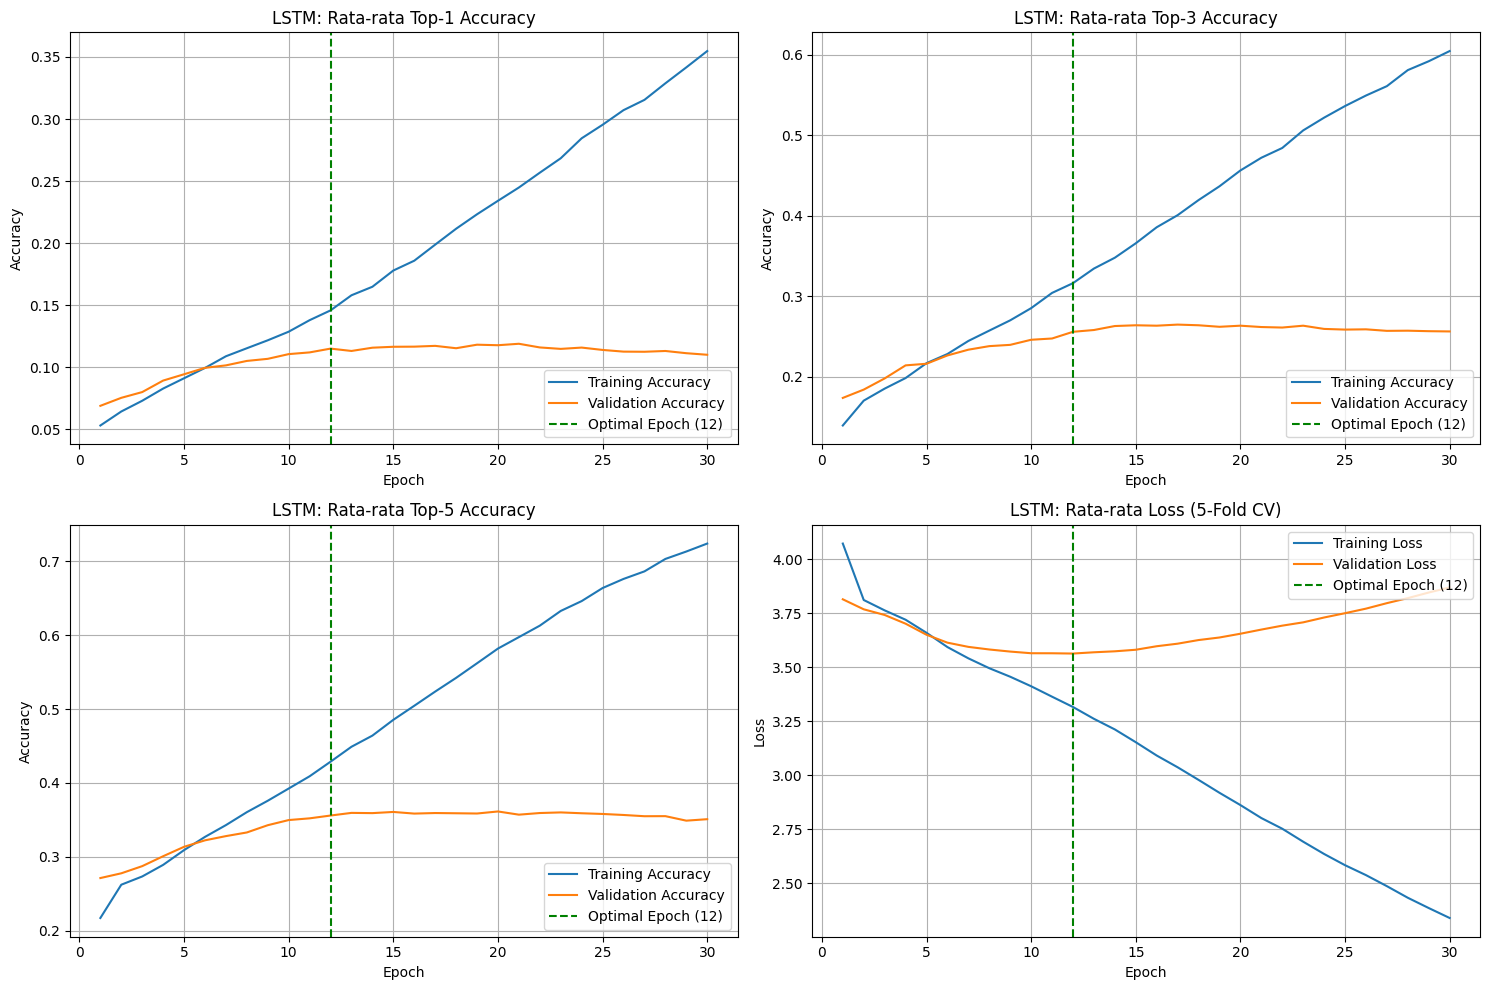

In [37]:
# ==============================================================================
# 5. VISUALISASI KURVA PEMBELAJARAN (TOP-1, TOP-3, TOP-5, DAN LOSS)
# ==============================================================================
epochs_range = range(1, MAX_EPOCHS + 1)
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

plot_configs = [
    (axs[0, 0], avg_top1_acc, avg_val_top1_acc, 'LSTM: Rata-rata Top-1 Accuracy', 'Accuracy', 'lower right'),
    (axs[0, 1], avg_top3_acc, avg_val_top3_acc, 'LSTM: Rata-rata Top-3 Accuracy', 'Accuracy', 'lower right'),
    (axs[1, 0], avg_top5_acc, avg_val_top5_acc, 'LSTM: Rata-rata Top-5 Accuracy', 'Accuracy', 'lower right'),
    (axs[1, 1], avg_loss, avg_val_loss, 'LSTM: Rata-rata Loss (5-Fold CV)', 'Loss', 'upper right')
]

for ax, train_metric, val_metric, title, ylabel, leg_loc in plot_configs:
    ax.plot(epochs_range, train_metric, label=f'Training {ylabel}')
    ax.plot(epochs_range, val_metric, label=f'Validation {ylabel}')
    ax.axvline(final_epoch_lstm, color='green', linestyle='--', label=f'Optimal Epoch ({final_epoch_lstm})')
    ax.set_title(title)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(loc=leg_loc)
    ax.grid(True)

plt.tight_layout()
plt.show()

In [41]:
# ==============================================================================
# 6. FINAL TRAINING LSTM PADA 100% DATASET UNTUK INTEGRASI MODEL HIBRIDA
# ==============================================================================
print("=" * 70)
print("FINAL TRAINING LSTM (100% DATASET)")
print("=" * 70)
print(f"Total Sequence     : {len(X_lstm)} baris ({len(np.unique(groups_lstm))} pertandingan)")
print(f"Epoch Optimal      : {final_epoch_lstm} epoch | Batch Size: {BATCH_SIZE}")

clear_session()
tf.keras.utils.set_random_seed(SEED)

final_lstm_model = build_lstm_model()
final_history_lstm = final_lstm_model.fit(
    X_lstm, y_lstm,
    epochs=final_epoch_lstm,
    batch_size=BATCH_SIZE,
    verbose=1
)

model_save_path = f'{MODEL_DIR}/lstm_draft_pick_model.keras'
final_lstm_model.save(model_save_path)
print(f"\nModel LSTM final berhasil disimpan di: '{model_save_path}'")
print("Catatan: Metrik training pada model final tidak digunakan sebagai klaim generalisasi.")

FINAL TRAINING LSTM (100% DATASET)
Total Sequence     : 9486 baris (558 pertandingan)
Epoch Optimal      : 12 epoch | Batch Size: 32
Epoch 1/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - loss: 4.0297 - top_1_acc: 0.0529 - top_3_acc: 0.1461 - top_5_acc: 0.2273
Epoch 2/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 3.7887 - top_1_acc: 0.0702 - top_3_acc: 0.1803 - top_5_acc: 0.2738
Epoch 3/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - loss: 3.7397 - top_1_acc: 0.0810 - top_3_acc: 0.1937 - top_5_acc: 0.2814
Epoch 4/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - loss: 3.6656 - top_1_acc: 0.0893 - top_3_acc: 0.2102 - top_5_acc: 0.2992
Epoch 5/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 11s 37ms/step - loss: 3.5909 - top_1_acc: 0.1015 - top_3_acc: 0.2348 - top_5_acc: 0.3247
Epoch 6/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 3.5426 - top_1_acc: 0.1069 - top_3_acc: 0.2488 - top_5_acc: 0.3443
Epoch 7/12
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 40ms/step - loss: 3.5002 - top_1_acc: 0.1181 - to

In [39]:
# ==============================================================================
# 7. FUNGSI UNTUK MENDAPATKAN REKOMENDASI SAAT DRAFT BERJALAN
# ==============================================================================
def prediksi_hero_selanjutnya(urutan_hero_sekarang, model, encoder, df_hero, MAX_INPUT_LENGTH):
    """
    Fungsi untuk menebak 3 hero apa yang paling mungkin di-pick selanjutnya menggunakan Nama Hero.
    Contoh penggunaan: prediksi_hero_selanjutnya(['Dharma', 'Mai_Shiranui'], model, encoder, df_hero, MAX_INPUT_LENGTH)
    """
    urutan_hero_id = []

    # 1. Terjemahkan Nama Hero menjadi Hero_ID menggunakan dataframe
    for nama in urutan_hero_sekarang:
        pencarian = df_hero[df_hero['Hero_Name'] == nama]
        if not pencarian.empty:
            urutan_hero_id.append(pencarian['Hero_ID'].values[0])
        else:
            print(f"Error: Hero dengan nama '{nama}' tidak ditemukan di database. Pastikan penulisan sama persis (Case-sensitive).")
            return

    # 2. Encode ID ke indeks model (+1)
    encoded_input = [encoder.transform([hero])[0] + 1 for hero in urutan_hero_id]

    # 3. Pad sequence agar ukurannya cocok dengan model
    padded_input = pad_sequences([encoded_input], maxlen=MAX_INPUT_LENGTH, padding='pre')

    # 4. Prediksi probabilitas (keluar array berisi probabilitas semua hero)
    prediksi_probabilitas = model.predict(padded_input, verbose=0)[0]

    # Setel probabilitas hero yang sudah dipilih/di-ban menjadi 0.0 (0%)
    for idx in encoded_input:
        prediksi_probabilitas[idx] = 0.0
    # ---------------------------------------------

    # 5. Ambil 5 indeks dengan probabilitas tertinggi
    top_5_indices = np.argsort(prediksi_probabilitas)[-5:][::-1]

    print(f"Urutan Draft Saat Ini: {urutan_hero_sekarang}")
    print("Top 5 Prediksi Hero Selanjutnya:")

    for idx in top_5_indices:
        if idx == 0: continue # Lewati padding

        # Kembalikan indeks ke ID hero asli (-1 karena tadi kita tambah 1)
        hero_id_asli = encoder.inverse_transform([idx - 1])[0]
        probabilitas = prediksi_probabilitas[idx] * 100

        # Ambil nama hero dari dataframe
        nama_hero = df_hero[df_hero['Hero_ID'] == hero_id_asli]['Hero_Name'].values[0]

        print(f"- {nama_hero} : {probabilitas:.2f}% peluang muncul")

In [40]:
# Contoh penggunaan:
# Misalkan hero yang sudah di-pick adalah Dharma dan Mai_Shiranui
# Untuk melihat daftar Hero_Name, Anda bisa melihat df_hero atau output sebelumnya.
# display(df_hero[['Hero_ID', 'Hero_Name']].head())

urutan_hero_sekarang = ['Dharma', 'Mai_Shiranui', 'Agudo', 'Luna', 'Pei'] # Ganti dengan NAMA hero yang sudah di-pick atau di-ban
encoder = global_params['encoder']
# Load hero dataframe
df_hero = pd.read_csv('Data/hero_data.csv')

# Pastikan menggunakan final_lstm_model, bukan variabel 'model' sisa loop CV
prediksi_hero_selanjutnya(urutan_hero_sekarang, final_lstm_model, encoder, df_hero, MAX_INPUT_LENGTH)

Urutan Draft Saat Ini: ['Dharma', 'Mai_Shiranui', 'Agudo', 'Luna', 'Pei']
Top 5 Prediksi Hero Selanjutnya:
- Arli : 34.93% peluang muncul
- Ao_Yin : 7.02% peluang muncul
- Biron : 6.97% peluang muncul
- Yuhuan : 6.50% peluang muncul
- Lian_Po : 4.51% peluang muncul
